# U-Net: Biomedical Image Segmentation

## Reference Paper

**Title:** U-Net: Convolutional Networks for Biomedical Image Segmentation

**Authors:** Olaf Ronneberger, Philipp Fischer, Thomas Brox

**Year:** 2015

**Paper:** https://arxiv.org/abs/1505.04597

## 1. Network Architecture

Implementation of the original U-Net architecture using PyTorch.


In [1]:
import sys
from pathlib import Path

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from src.unet import UNet

torch.manual_seed(42)

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.15.0
Device: mps


In [2]:
model = UNet(
    in_channels=1,
    num_classes=2
).to(device)

model.eval()

print(model)

UNet(
  (encoder): Encoder(
    (enc1): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
        (3): ReLU(inplace=True)
      )
    )
    (enc2): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
        (3): ReLU(inplace=True)
      )
    )
    (enc3): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
        (3): ReLU(inplace=True)
      )
    )
    (enc4): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(512, 512, kernel_size=(3, 3), stride=

In [3]:
x = torch.randn(1, 1, 572, 572).to(device)

with torch.inference_mode():
    output = model(x)

print("Input shape :", x.shape)
print("Output shape:", output.shape)

assert output.shape == (1, 2, 388, 388)

Input shape : torch.Size([1, 1, 572, 572])
Output shape: torch.Size([1, 2, 388, 388])


In [4]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

conv_layers = sum(
    isinstance(layer, (nn.Conv2d, nn.ConvTranspose2d))
    for layer in model.modules()
)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Convolutional layers: {conv_layers}")

assert conv_layers == 23

Total parameters:     31,030,658
Trainable parameters: 31,030,658
Convolutional layers: 23


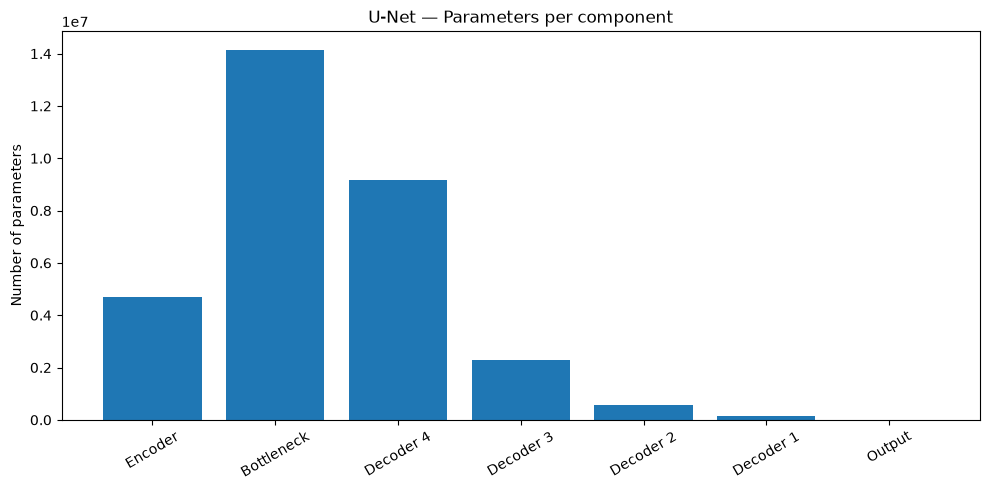

In [5]:
components = {
    "Encoder": model.encoder,
    "Bottleneck": model.bottleneck,
    "Decoder 4": model.dec4,
    "Decoder 3": model.dec3,
    "Decoder 2": model.dec2,
    "Decoder 1": model.dec1,
    "Output": model.output
}

params = {
    name: sum(p.numel() for p in module.parameters())
    for name, module in components.items()
}

plt.figure(figsize=(10, 5))

plt.bar(params.keys(), params.values())

plt.ylabel("Number of parameters")
plt.title("U-Net — Parameters per component")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

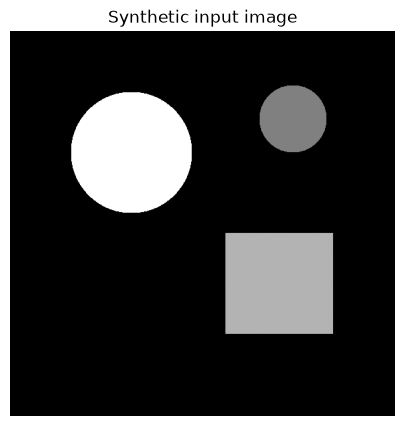

In [6]:
size = 572

y, x = np.ogrid[:size, :size]

image = np.zeros((size, size), dtype=np.float32)

# Circle
image[(x - 180)**2 + (y - 180)**2 < 90**2] = 1.0

# Rectangle
image[300:450, 320:480] = 0.7

# Second circle
image[(x - 420)**2 + (y - 130)**2 < 50**2] = 0.5

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray")
plt.title("Synthetic input image")
plt.axis("off")
plt.show()

In [7]:
input_tensor = torch.from_numpy(image)
input_tensor = input_tensor.unsqueeze(0).unsqueeze(0)
input_tensor = input_tensor.to(device)

model.eval()

with torch.inference_mode():
    encoded, features = model.encoder(input_tensor)

for i, feature in enumerate(features, 1):
    print(f"Encoder {i}: {feature.shape}")

Encoder 1: torch.Size([1, 64, 568, 568])
Encoder 2: torch.Size([1, 128, 280, 280])
Encoder 3: torch.Size([1, 256, 136, 136])
Encoder 4: torch.Size([1, 512, 64, 64])


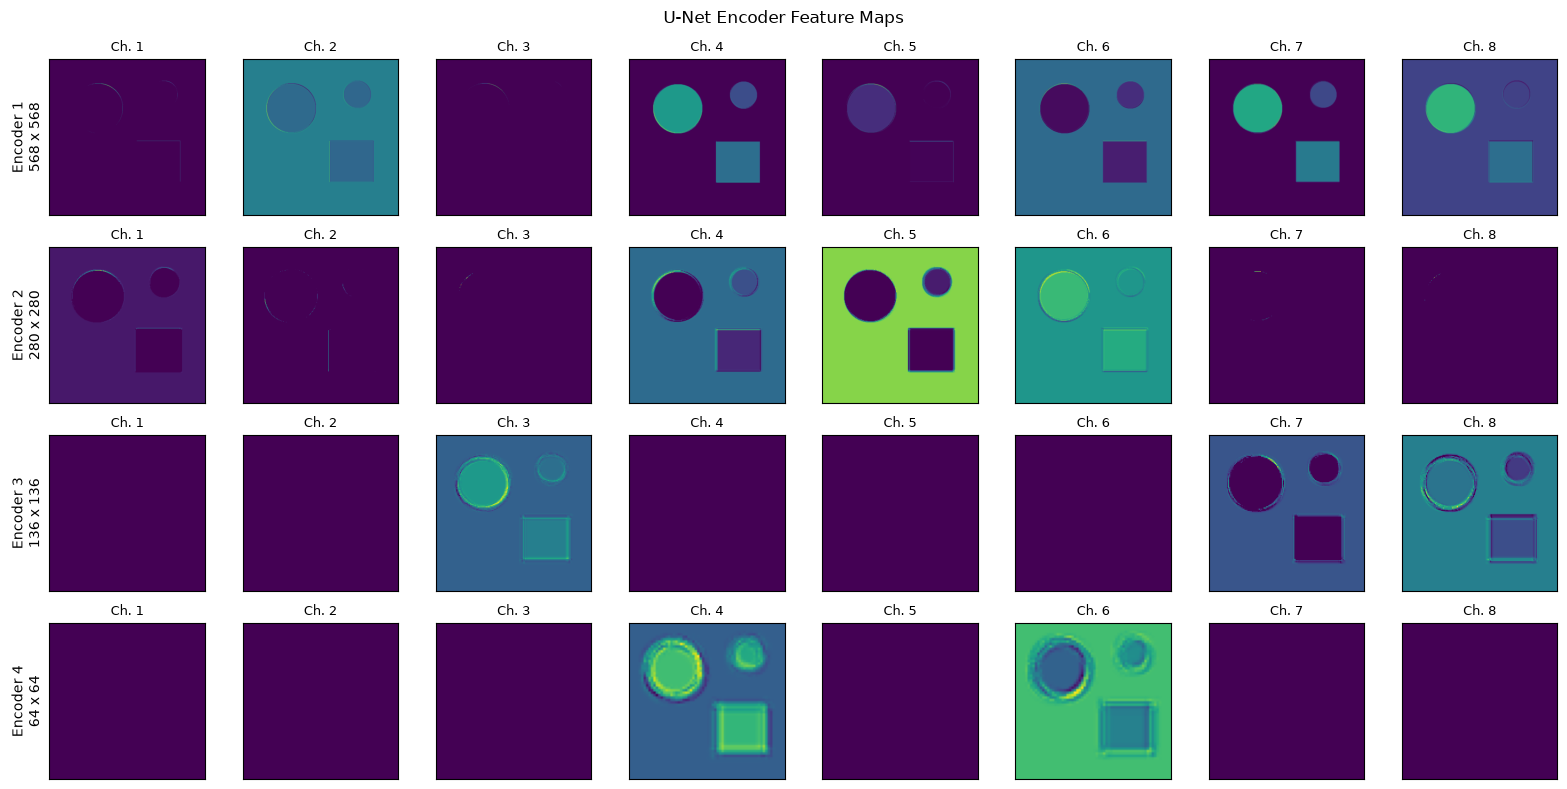

In [8]:
fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for level, feature in enumerate(features):

    maps = feature[0].detach().cpu().numpy()

    for channel in range(8):

        ax = axes[level, channel]

        ax.imshow(maps[channel], cmap="viridis")
        ax.set_title(f"Ch. {channel + 1}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

    axes[level, 0].set_ylabel(
        f"Encoder {level + 1}\n{maps.shape[1]} x {maps.shape[2]}"
    )

plt.suptitle("U-Net Encoder Feature Maps")
plt.tight_layout()
plt.show()

In [9]:
fig.savefig(
    ROOT / "results" / "encoder_feature_maps.png",
    dpi=200,
    bbox_inches="tight"
)

## 2. Architecture Analysis

The implemented U-Net architecture follows the original
network proposed by Ronneberger et al. (2015).

### Observations

- The network contains 23 convolutional layers.
- The input resolution is 572 × 572 pixels.
- The output resolution is 388 × 388 pixels.
- The bottleneck contains the largest number of parameters.
- Spatial resolution progressively decreases throughout
  the contracting path.
- Skip connections transfer spatial information from the
  encoder to the decoder.

### Feature Map Analysis

The visualization illustrates how different convolutional
filters respond to a synthetic input image.

Some feature maps highlight geometric shapes and boundaries,
while others exhibit weak or constant activations.

Since the network has not been trained yet, these feature
maps represent responses from randomly initialized filters
rather than learned semantic representations.